# **Trabajo final: Métodos de Análisis de datos**

**Universidad Nacional del Sur**

**Alumno:** Martín Godoy

**Profesor:** José Bavio

---

---


## **Importamos las librerías**

In [1]:
#Importamos librerías necesarias
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix
warnings.filterwarnings('ignore')

#Configuramos
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

print("Librerías importadas correctamente")


Librerías importadas correctamente


---

---

## **Cargado de datos en DataFrame**

In [2]:
#Hacemos dataframe's de cada uno de los csv's y luego los concatenamos
df1 = pd.read_csv('Monday-WorkingHours.pcap_ISCX.csv')
df2 = pd.read_csv('Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv')
df3 = pd.read_csv('Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv')
df4 = pd.read_csv('Wednesday-workingHours.pcap_ISCX.csv')
df5 = pd.read_csv('Tuesday-WorkingHours.pcap_ISCX.csv')
df6 = pd.read_csv('Friday-WorkingHours-Morning.pcap_ISCX.csv')
df7 = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
df8 = pd.read_csv('Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv')

#Concatenamos todos los dataframe's
df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8], ignore_index=True)
print("El dataframe concatenado tiene {} filas y {} columnas".format(df.shape[0], df.shape[1]))

El dataframe concatenado tiene 2830743 filas y 79 columnas


Luego de crear el DataFrame que contiene los datos de los 5 días se debe realizar una limpieza de los mismos. Esto porque, se reportan valores duplicados, valores faltantes y valores infinitos, ademas, en la columna 'Label' existen variantes de los tipos de ataque con diferencias en mayúsculas, espacios y guiones.

Se realizaran a continuación, con el fin de limpiar los datos:
- Eliminación de duplicados.
- Trata de valores faltantes.
- Eliminación de valores infinitos
- Consolidación de etiquetas.

---

---

## **Limpieza del DataFrame**

Primero eliminamos los valores duplicados, deberían reportarse 308.381 duplicados, una vez verificado nos deshacemos de ellos.

In [3]:
# Eliminamos duplicados
print("Duplicados antes:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicados después:", df.duplicated().sum())

Duplicados antes: 308381
Duplicados después: 0


Una vez eliminados duplicados, verificamos valores nulos. Luego de verificar que haya 353 valores faltantes, los imputamos con la media de cada columna.

In [4]:
# Vemos cantidad de valores faltantes
print("Valores faltantes antes:", df.isnull().sum().sum())

# Creamos una copia temporal para calcular las medias (para evitar problemas con valores infinitos)
df_temp = df.replace([np.inf, -np.inf], np.nan)

# Calculamos la media de cada columna numérica
medias = df_temp.select_dtypes(include=np.number).mean()

# Imputamos los valores faltantes con las medias calculadas
df.fillna(medias, inplace=True)

print("Valores faltantes después:", df.isnull().sum().sum())

Valores faltantes antes: 353
Valores faltantes después: 0


Se reportan también, columnas que presentan valores $\pm \infty$, nos deshacemos de los mismos eliminando las filas del DataFrame que los contengan.

In [5]:
# Detectamos valores infinitos
print("\nValores infinitos antes:", df.isin([np.inf, -np.inf]).any().sum())

df = df[~df.isin([np.inf, -np.inf]).any(axis=1)]

print("Valores infinitos después:", df.isin([np.inf, -np.inf]).any().sum())


Valores infinitos antes: 2
Valores infinitos después: 0


Por ultimo, pasamos con la consolidación de etiquetas de la columna 'Label', el objetivo es consolidar etiquetas similares bajo una misma categoría. Etiquetas que contengan:
- "Web Attack" entran en la categoría "Web Attack".
- "DoS" entran en la categoría "DoS".
- "DDoS" entran en la categoría "DDoS".
- "PortScan" entran en la categoría "PortScan".
- "Bot" entran en la categoría "Bot".
- "BENIGN" entran en la categoría "BENIGN".
- El resto entra en la categoría "Other"

In [6]:
# Consolidamos las etiquetas de la columna 'Label'
df[' Label']= df[' Label'].str.strip().str.lower()

print("\nEtiquetas únicas antes de la consolidación:\n", df[' Label'].unique())
print("\nCantidad de valores antes de la consolidación:\n", df[' Label'].value_counts())

# Clasificamos etiquetas simples bajo una categoría común
df[' Label'] = np.select(
    [
        df[' Label'].str.contains('Web Attack', case=False, na=False),
        df[' Label'].str.contains('DDoS', case=False, na=False),
        df[' Label'].str.contains('DoS', case=False, na=False),
        df[' Label'].str.contains('PortScan', case=False, na=False),
        df[' Label'].str.contains('Bot', case=False, na=False),
        df[' Label'].str.upper().eq('BENIGN')
    ],
    [
        'Web Attack',
        'DDoS',
        'DoS',
        'PortScan',
        'Bot',
        'BENIGN'
    ],
    default='Other'
)

print("\nCantidad de valores después de la consolidación:\n", df[' Label'].value_counts())
print("\nEtiquetas únicas después de la consolidación:\n", df[' Label'].unique())


Etiquetas únicas antes de la consolidación:
 <StringArray>
[                    'benign',   'web attack � brute force',
           'web attack � xss', 'web attack � sql injection',
               'infiltration',              'dos slowloris',
           'dos slowhttptest',                   'dos hulk',
              'dos goldeneye',                 'heartbleed',
                'ftp-patator',                'ssh-patator',
                        'bot',                       'ddos',
                   'portscan']
Length: 15, dtype: str

Cantidad de valores antes de la consolidación:
  Label
benign                        2095057
dos hulk                       172846
ddos                           128014
portscan                        90694
dos goldeneye                   10286
ftp-patator                      5931
dos slowloris                    5385
dos slowhttptest                 5228
ssh-patator                      3219
bot                              1948
web attack � brute forc

De esta forma, nos deshicimos de las variantes textuales de los tipos de ataque y nos quedamos unicamente con las categorías 'BENIGN', 'DoS', 'DDoS', 'PortScan', 'Web Attack', 'Bot' y 'Other'.

Con esto concluye la etapa de limpieza de el DataFrame.

---

---

## **Escalado y balanceo de clases**

Antes de comenzar con el proceso de escalado y balanceo de columnas numéricas, dividimos los datos de el DataFrame en conjuntos para entrenamiento y prueba.

In [7]:
# Asignamos Y a la columna 'Label' y X a todas las demás columnas
X = df.drop(columns=[' Label'])
Y = df[' Label']

# Hacemos la división de los datos en conjuntos de entrenamiento y prueba
X_train, X_test, Y_train, Y_test = train_test_split(
    X, 
    Y, 
    test_size=0.2, # Utilizamos una distribución 80/20 para entrenamiento y prueba
    random_state=42,
    stratify=Y  # Mantenemos proporción de clases en ambos conjuntos
)

Se separaron los datos del DataFrame en conjuntos de entrenamiento y test para la futura implementación de los métodos "Naive Bayes" y "MLP".

A continuación se realiza un escalado de las variables numéricas. Este paso tiene como objetivo la estandarización de las variables numéricas (que resulten con media aproximadamente 0 y desvió aproximadamente 1), pues una gran diferencia en escala de las variables puede perjudicar a el desempeño de los algoritmos.

In [8]:
# Creamos un objeto StandardScaler 
scaler = StandardScaler()

# Le pasamos X_train al scaler para que aprenda parámetros de escalado (media y desviación estándar)
scaler.fit(X_train)

# Transformamos X_train y X_test 
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

Una vez estandarizados los datos de los conjuntos entrenamiento y test pasamos con el balanceo de clases utilizando SMOTE, concretamente lo aplicamos a el conjunto de entrenamiento. Este paso resulta importante porque el DataSet presenta un gran desbalace de clases, concretamente, la clase 'BENIGN' domina en cantidad a el resto de clases. Para solucionar este problema, la técnica SMOTE genera sobre el conjunto de entrenamiento muestras sintéticas de las clases minoritarias.

In [9]:
# Creamos un objeto SMOTE para balancear las clases
smote = SMOTE(random_state=42)

# Aplicamos SMOTE para generar nuevas muestras sintéticas de las clases minoritarias
X_train_smote, Y_train_smote = smote.fit_resample(
    X_train_scaled, 
    Y_train
)

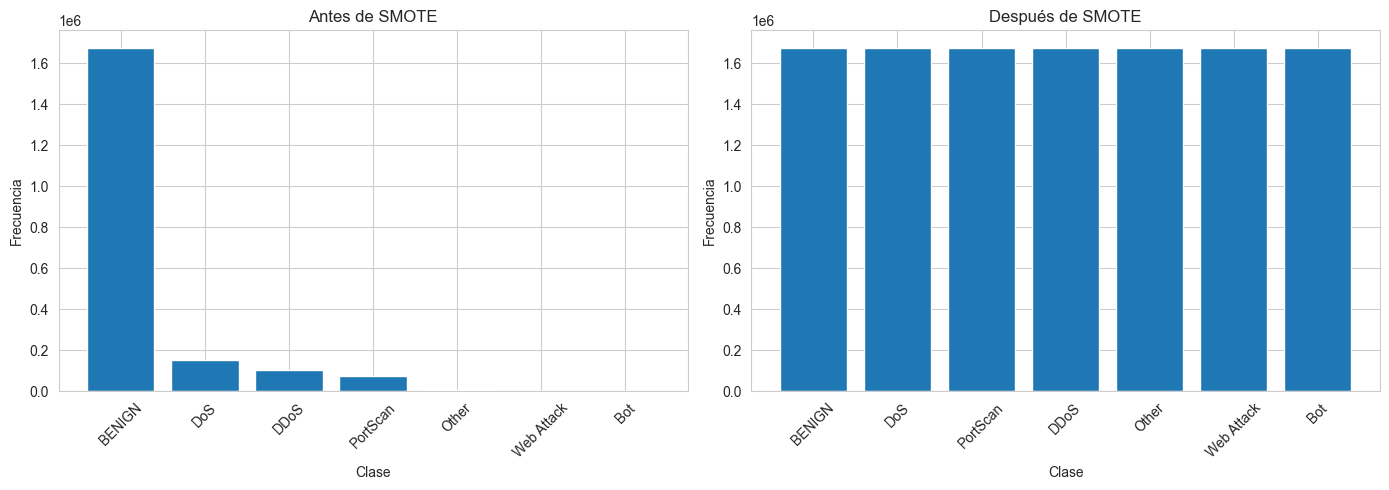

In [10]:
# Cantidad de observaciones por clase
antes_smote = Y_train.value_counts()
despues_smote = Y_train_smote.value_counts()

plt.figure(figsize=(14, 5))

# Gráfico 1: Antes de SMOTE
plt.subplot(1, 2, 1)
plt.bar(antes_smote.index, antes_smote.values)
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.title('Antes de SMOTE')
plt.xticks(rotation=45)

# Gráfico 2: Después de SMOTE
plt.subplot(1, 2, 2)
plt.bar(despues_smote.index, despues_smote.values)
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.title('Después de SMOTE')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Luego de utilizar SMOTE se aprecia que ahora todas las clases están balanceadas, presentando la misma cantidad de muestras cada una.

---

---

## **Selección de features**

Una vez finalizado el proceso de balanceo y escalado, continuamos con la selección de features especificas. El criterio de selección de features que se utilizara consiste en eliminar, para cada par con correlación absoluta mayor a 0,85, alguna de las dos features de ese par. Para ello calcularemos la matriz de correlación entre features.

In [11]:
# El Standarscaler y el SMOTE devuelven un array de numpy, convertimos X_train_smote a un DataFrame
X_train_smote = pd.DataFrame(X_train_smote, columns=X_train.columns)

# Calculamos la matriz de correlación absoluta para el conjunto de entrenamiento balanceado
corr_matrix = X_train_smote.corr().abs()

# Lista de variables a eliminar
columnas_a_eliminar = []

# Encontramos las características altamente correlacionadas (umbral de 0.85)
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        
        if corr_matrix.iloc[i, j] > 0.85:
            
            columna_1 = corr_matrix.columns[i]
            columna_2 = corr_matrix.columns[j]
            
            print(
                f"Correlación alta: {columna_1} - {columna_2} "
                f"({corr_matrix.iloc[i, j]:.2f})"
            )
            
            if columna_1 not in columnas_a_eliminar:
                columnas_a_eliminar.append(columna_1)

print("\nCantidad de variables a eliminar debido a alta correlación:", len(columnas_a_eliminar))
print("Variables a eliminar:")
print(columnas_a_eliminar)


Correlación alta:  Total Backward Packets -  Total Fwd Packets (1.00)
Correlación alta:  Total Length of Bwd Packets -  Total Fwd Packets (0.99)
Correlación alta:  Total Length of Bwd Packets -  Total Backward Packets (0.99)
Correlación alta:  Fwd Packet Length Mean -  Fwd Packet Length Max (0.96)
Correlación alta:  Fwd Packet Length Std -  Fwd Packet Length Max (0.96)
Correlación alta:  Fwd Packet Length Std -  Fwd Packet Length Mean (0.95)
Correlación alta:  Bwd Packet Length Mean - Bwd Packet Length Max (0.97)
Correlación alta:  Bwd Packet Length Std - Bwd Packet Length Max (0.99)
Correlación alta:  Bwd Packet Length Std -  Bwd Packet Length Mean (0.96)
Correlación alta:  Flow IAT Std -  Flow Duration (0.92)
Correlación alta:  Flow IAT Max -  Flow Duration (0.95)
Correlación alta:  Flow IAT Max -  Flow IAT Std (0.97)
Correlación alta: Fwd IAT Total -  Flow Duration (1.00)
Correlación alta: Fwd IAT Total -  Flow IAT Std (0.92)
Correlación alta: Fwd IAT Total -  Flow IAT Max (0.95)
Co

Gracias a la matriz fueron detectadas features que estaban altamente relacionadas (con una correlación absoluta mayor a 0,85). Se fueron tomando de a pares para compararse entre si y se eligieron de manera arbitraria las 1ras de ese par para ser eliminadas. 

A continuación realizamos el proceso de eliminación de esas features en el conjunto de entrenamiento.

In [12]:
# Eliminamos las columnas altamente correlacionadas del conjunto de entrenamiento y prueba
X_train_final = X_train_smote.drop(columns=columnas_a_eliminar)

# Transformamos X_test_scaled a DataFrame para eliminar las mismas columnas
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_test_final = X_test_scaled_df.drop(columns=columnas_a_eliminar)

print("Dimensiones finales del conjunto de entrenamiento:", X_train_final.shape)   
print("Dimensiones finales del conjunto de prueba:", X_test_final.shape)

Dimensiones finales del conjunto de entrenamiento: (11732315, 43)
Dimensiones finales del conjunto de prueba: (504160, 43)


Una vez habiendo eliminado las features altamente correlacionadas correctamente y previo a realizar la implementación de los modelos 'Naive Bayes' y 'MLP' veamos como resultaron nuestros conjuntos.

In [13]:
print("Train:", X_train_final.shape)
print("Test:", X_test_final.shape)

# Nos interesa conocer la cantidad de features finales y que el conjunto de entrenamiento y prueba tengan la misma cantidad de features
print("\nCantidad de features:")
print("Train:", X_train_final.shape[1])
print("Test:", X_test_final.shape[1])

print("\nClases en train:")
print(Y_train_smote.value_counts())

print("\nClases en test:")
print(Y_test.value_counts())

Train: (11732315, 43)
Test: (504160, 43)

Cantidad de features:
Train: 43
Test: 43

Clases en train:
 Label
BENIGN        1676045
DoS           1676045
PortScan      1676045
DDoS          1676045
Other         1676045
Web Attack    1676045
Bot           1676045
Name: count, dtype: int64

Clases en test:
 Label
BENIGN        419012
DoS            38749
DDoS           25603
PortScan       18139
Other           1839
Web Attack       429
Bot              389
Name: count, dtype: int64


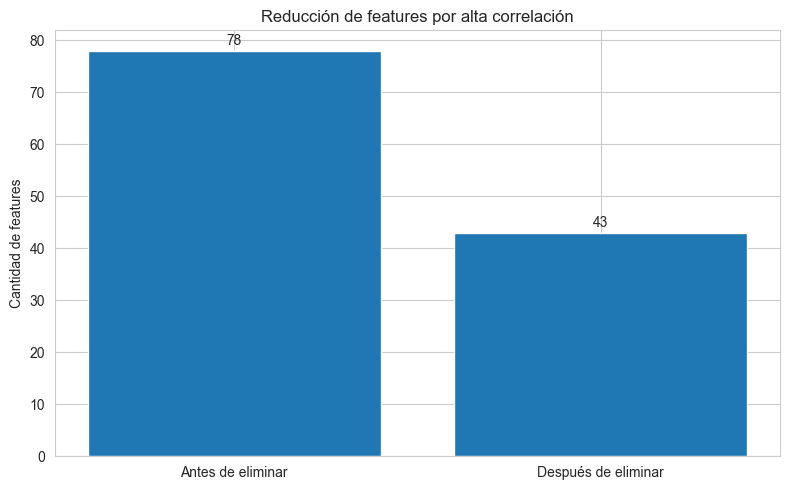

In [14]:
# Cantidad de features antes y después
features_antes = X_train_smote.shape[1]
features_despues = X_train_final.shape[1]

# Datos para el gráfico
etapas = ['Antes de eliminar', 'Después de eliminar']
cantidad_features = [features_antes, features_despues]

# Gráfico
plt.figure(figsize=(8, 5))

plt.bar(etapas, cantidad_features)

plt.ylabel('Cantidad de features')
plt.title('Reducción de features por alta correlación')

# Mostrar el valor encima de cada barra
for i, valor in enumerate(cantidad_features):
    plt.text(i, valor + 1, str(valor), ha='center')

plt.tight_layout()
plt.show()

A pesar de que la cantidad de filas de los conjuntos train y test difieran bastante ($11.732.315 \text{ y } 504.160$ respectivamente) esto se debe a el trabajo que realizo SMOTE sobre el conjunto de entrenamiento, por lo que es un resultado esperable, también se aprecia que la cantidad de features en ambos conjuntos coinciden, que es un resultado muy positivo.

Observando las clases de train y test, podemos ver que hay una clara diferencia de balance, en el primer caso todas las clases están bien balanceadas, pero las clases de test no. Esto podría llamar la atención, pero tiene sentido dado que el balance existente en las clases de train es artificialmente creado por el balanceo hecho sobre las mismas, es importante que las clases de test permanezcan desbalanceadas pues, de este modo, reflejan mejor la realidad y asi se representara mejor el comportamiento de el modelo sobre datos no vistos.

---

---

## **Presentación de modelos: Naive Bayes y MLP**

### MLP

El MLP es una red neuronal feedforward que aprende una función mediante la composición de transformaciones realizadas por diferentes capas, formadas por neuronas artificiales. Los datos de entrada van pasando de una a otra, primero pasando por una capa de entrada, luego algunas capas ocultas y por ultimo llegando a la capa de salida. La primera recibe los datos crudos, las capas ocultas procesan la información de manera intermedia y la capa de salida muestra el resultado o predicción final del modelo. 

Una forma de pensar a MLP es, partiendo con un modelo lineal, considerar como podrían superarse las limitaciones de los mismos. Los modelos lineales poseen un defecto, su capacidad, esta está limitada a funciones lineales incapaz de entender interacciones entre dos variables de entrada. Para el MLP, la incorporación de funciones de activation no lineales (por defecto ReLU), le permite representar relaciones que modelos lineales son incapaces de representar, el entrenamiento de el mismo, se realiza mediante métodos de optimización basados en gradientes.

Los hiperparámetros principales de la MLP son: 
- Profundidad: Es la cantidad de capas que tiene el modelo. Las redes mas profundas son capaces de representar ciertas funciones de manera mas eficiente que las poco profundas, sin embargo, esta eficiencia en representación dificulta el proceso de optimización.
- Ancho: Representa la cantidad de unidades/neuronas que posee cada capa oculta. La cantidad de neuronas que posea una capa oculta determina su capacidad de representación, es decir, que mientras mas cantidad de neuronas haya por capa, el modelo sera capaz de resolver problemas mas complejos. Sin embargo, a pesar de que un MLP con una sola capa oculta podría representar ciertas funciones de manera adecuada, ajustando solamente el Ancho del modelo, una arquitectura con mayor profundidad podría lograr una representación mas eficiente. 
- Función de activación: Son las funciones que introducen la no linealidad que le permiten a la red aprender funciones no representables por un modelo puramente lineal, en general una elección por defecto particularmente buena suele ser ReLU. Si la función de activación elegida no fuese adecuada, puede causar que el modelo tenga dificultades para el aprendizaje mediante gradiente, con muchas capas, puede traer dificultades para el entrenamiento de redes profundas, y eventualmente, limitaría la capacidad de la red.
- Método de optimización: El método de optimización determina como son modificados los parámetros de la red durante el entrenamiento por medio de los gradientes de la función de pérdida. La elección de el mismo influye en la forma y eficiencia con la que es realizada la optimización.
- Inicialización de parámetros: Son los parámetros con los que comienza la red previo al entrenamiento y el resultado de la optimización puede depender de estos. El punto al que converge el descenso por el gradiente puede depender de estos valores iniciales.

**Fortalezas de MLP** 
- Capacidad de representación de funciones no lineales: Mientras que los modelos lineales son capaces unicamente de representar funciones lineales, los MLP con sus capas ocultas, proporcionan un marco para aproximar funciones no lineales. Existe también un teorema de aproximación universal: Una red feedforward con al menos una capa oculta y suficientes unidades, es capaz de aproximar una amplia clase de funciones con un error muy pequeño.
- Representaciones mediante profundidad: Las arquitecturas profundas son capaces de representar determinadas funciones de manera mas eficiente que las redes poco profundas.

**Limitaciones de MLP**
- Dificultad de optimización: Debido a las no linealidades, las funciones de perdida de las redes neuronales suelen ser no convexas. Esto dificulta el entrenamiento en determinados modelos lineales o problemas no convexos. Ademas, aumentar la profundidad puede resultar en que el entrenamiento sea mas difícil.
- Capacidad de representación y entrenamiento: A pesar de lo antes mencionado con el teorema de aproximación universal que indica que una red suficientemente grande puede representar una función, esto no garantiza que el algoritmo de entrenamiento consiga aprenderla finalmente.

### Naive Bayes

Naive Bayes es un método de clasificación probabilístico que estima la probabilidad de pertenencia de una observación a cada clase a partir de sus características. Para lograrlo, utiliza un supuesto de independencia condicional entre características cuando se conoce la clase. Esto le permite, en lugar de estimar directamente una distribución conjunta de todas las variables, estimar una distribución para cada característica en cada clase y se combinan mediante un producto. A pesar de que la independencia condicional generalmente no es cierta, la suposición de la misma simplifica en gran medida la estimación y resulta especialmente apropiada cuando existe una gran cantidad de características.

La estructura del modelo se basa en representar la densidad de cada clase como el producto de las densidades marginales de sus características: $$f_j(X) = \displaystyle \prod_{k=1}^p f_{jk} (X_k)$$
Y las distribuciones de las características pueden ser estimadas individualmente, en procedimientos originales de Naive Bayes eran utilizadas distribuciones gaussianas univariadas.

A diferencia de MLP, Naive Bayes posee una cantidad reducida de hiperparámetros relevantes, pues su estructura es determinada principalmente por el supuesto de independencia condicional y por el modelo a utilizar para estimar las distribuciones de las variables.

**Fortalezas de Naive Bayes:**
Su principal ventaja es la considerable simplificación de la estimación que produce el supuesto de independencia. Ademas, es especialmente apropiado para espacios de características de alta dimension y puede obtener muy buenos resultados, aun frente a métodos mas sofisticados.

**Limitaciones de Naive Bayes:**
La principal limitación de el modelo, pese a todo, es el supuesto de independencia condicional, que generalmente no se verifica. Esto significa que, si nuestras características están relacionadas entre sí, el modelo utiliza una simplificación que no representa completamente la realidad. Y como se menciono anteriormente, la suposición puede introducir sesgo en la estimación de las distribuciones.

---

---

## **Implementación de los modelos**

Implementamos el modelo de Gaussian Naive Bayes

In [15]:
# Creamos un modelo de Naive Bayes
modelo_nb = GaussianNB()

# Entrenamos el modelo con el conjunto de entrenamiento
modelo_nb.fit(X_train_final, Y_train_smote)

# Hacemos predicciones sobre el conjunto de prueba
y_pred_nb = modelo_nb.predict(X_test_final)

Una vez hechas las predicciones, las contrastamos con el conjunto 'Y_test' y evaluamos el desempeño de el modelo. Al momento de calcular 'precision' y 'recall' las calculamos utilizando 'weighted', esta opción, pondera cada clase según la cantidad de ejemplos que hay en 'Y_test'.

In [16]:
# Calculamos la accuracy del modelo
accuracy = accuracy_score(Y_test, y_pred_nb)

# Calculamos la precisión
precision = precision_score(Y_test, y_pred_nb, average='weighted')

# Calculamos el recall
recall = recall_score(Y_test, y_pred_nb, average='weighted')

# Calculamos el F1-score weighted
f1_weighted = f1_score(Y_test, y_pred_nb, average='weighted')

# Calculamos F1-score macro
f1_macro = f1_score(Y_test, y_pred_nb, average='macro')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1-score (weighted): {f1_weighted:.4f}")
print(f"F1-score (macro): {f1_macro:.4f}")

Accuracy: 0.6196
Precision (weighted): 0.9254
Recall (weighted): 0.6196
F1-score (weighted): 0.7097
F1-score (macro): 0.4286


Nos quedamos entonces concretamente con: Accuracy $\approx 61.96\% $, F1-score (macro)$\approx 42.86 \% $, F1-score (ponderado)$\approx 70.97\% $

A continuación implementamos el modelo MLP.

In [17]:
# Creamos el modelo MLP 
mlp_model = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', solver='adam', batch_size=4096, max_iter=20, random_state=42)

# Entrenamos el modelo con el conjunto de entrenamiento
mlp_model.fit(X_train_final, Y_train_smote)

# Hacemos predicciones sobre el conjunto de prueba
y_pred_mlp = mlp_model.predict(X_test_final)

De igual forma que con Naive Bayes, se contrasta con el conjunto 'Y_test' y evaluamos el desempeño.

In [18]:
# Calculamos la accuracy del modelo
accuracy_mlp = accuracy_score(Y_test, y_pred_mlp)

# Calculamos la precisión
precision_mlp = precision_score(Y_test, y_pred_mlp, average='weighted')

# Calculamos el recall
recall_mlp = recall_score(Y_test, y_pred_mlp, average='weighted')

# Calculamos el F1-score weighted
f1_weighted_mlp = f1_score(Y_test, y_pred_mlp, average='weighted')

# Calculamos F1-score macro
f1_macro_mlp = f1_score(Y_test, y_pred_mlp, average='macro')

print(f"Accuracy (MLP): {accuracy_mlp:.4f}")
print(f"Precision (weighted) (MLP): {precision_mlp:.4f}")   
print(f"Recall (weighted) (MLP): {recall_mlp:.4f}")
print(f"F1-Score (weighted) (MLP): {f1_weighted_mlp:.4f}")
print(f"F1-Score (macro) (MLP): {f1_macro_mlp:.4f}")

Accuracy (MLP): 0.9661
Precision (weighted) (MLP): 0.9816
Recall (weighted) (MLP): 0.9661
F1-Score (weighted) (MLP): 0.9721
F1-Score (macro) (MLP): 0.7264


Nos quedamos con: Accuracy $\approx 96.61\% $, F1-score (macro)$\approx 72.64 \% $, F1-score (ponderado)$\approx 97.21\% $

Contrastando los resultados, se tiene:

- Resultados reportados por el paper:

| Métrica | Naive Bayes | MLP (Multilayer Perceptron) |
| ------- | ----------- | --------------------------- |
| Accuracy | $64.59\%$ | $97.00\%$ |
| F1-score (macro) | $48.7\%$ | $82\%$ |
| F1-score (ponderado) | $71\%$ | $98\%$ | 

- Resultados obtenidos: 

| Métrica | Naive Bayes | MLP (Multilayer Perceptron) |
| ------- | ----------- | --------------------------- |
| Accuracy | $61.96\%$ | $96.61\%$ |
| F1-score (macro) | $42.86\%$ | $72.64\%$ |
| F1-score (ponderado) | $70.97\%$ | $97.21\%$ | 

Se pueden apreciar diferencias en ambos resultados, en nuestro caso, a pesar de que hay valores similares el desempeño parece ser peor. Para el MLP, su baja de desempeño puede ser explicada mayormente por diferencias en hiperparámetros considerados, pues, al momento de seleccionarlos debía tenerse en consideración que el tiempo de compilado no fuese excesivo y, que los resultados no fuesen tan distintos. Por otro lado, en cuanto a la baja de desempeño de Naive Bayes, puede deberse a la asignación aleatoria al momento de dividir el dataset en conjuntos train-test, que es posible que haya diferido con la realizada en el paper y por eso se haya dado una pequeña baja en desempeño.

Podemos también, una vez calculadas las predicciones calcular las matrices de confusion para ambos modelos, con el fin de medir su rendimiento. Para visualizarla utilizamos un mapa de calor.

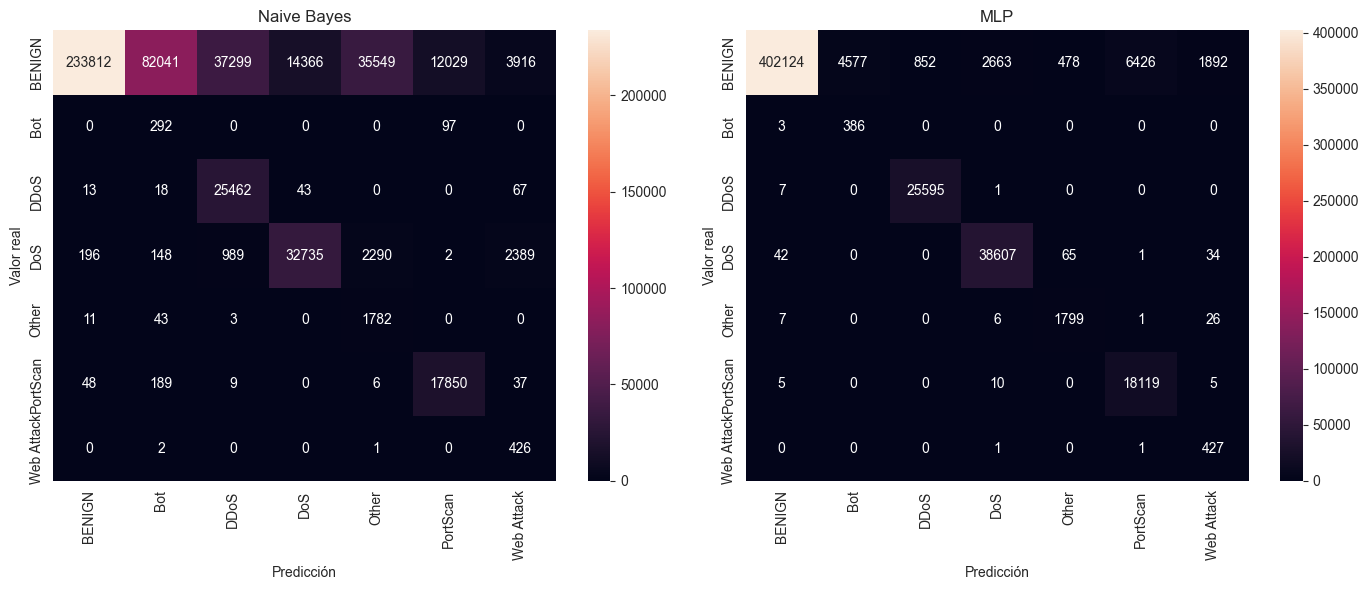

In [20]:
# Clases
clases = sorted(Y_test.unique())

# Matrices de confusión
cm_nb = confusion_matrix(Y_test, y_pred_nb, labels=clases)
cm_mlp = confusion_matrix(Y_test, y_pred_mlp, labels=clases)

# Figura con las dos matrices
plt.figure(figsize=(14, 6))

# Naive Bayes
plt.subplot(1, 2, 1)
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    xticklabels=clases,
    yticklabels=clases
)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Naive Bayes')

# MLP
plt.subplot(1, 2, 2)
sns.heatmap(
    cm_mlp,
    annot=True,
    fmt='d',
    xticklabels=clases,
    yticklabels=clases
)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('MLP')

plt.tight_layout()
plt.show()

---

## **Análisis**

Los resultados obtenidos por este experimento, en términos de accuracy y F1 son:
- Para MLP: Accuracy $\approx 96.61\% $, F1-score (macro)$\approx 72.64 \% $, F1-score (ponderado)$\approx 97.21\% $
- Para Naive Bayes: Accuracy $\approx 61.96\% $, F1-score (macro)$\approx 42.86 \% $, F1-score (ponderado)$\approx 70.97\% $

Se puede apreciar una clara superioridad en métricas de MLP con respecto a Naive Bayes.

Es razonable que MLP mostrara un desempeño superior. A diferencia de los modelos lineales, las redes neuronales pueden capturar relaciones complejas y no lineales presentes en el dataset CICIDS-2017. Naive Bayes asume independencia condicional entre variables dada la clase, sin embargo, en el tráfico de red las variables están fuertemente conectadas, degradando la capacidad predictiva del modelo.

El escenario ideal para un MLP es un conjunto de datos con un volumen masivo de observaciones y patrones no lineales complejos. La gran cantidad de registros evita el sobreajuste en el MLP y permite ajustar sus parámetros efectivamente. Aunque Naive Bayes escala muy bien en espacios de alta dimensionalidad, colapsa cuando las variables no son independientes entre sí, como ocurre en este caso.

El costo computacional para la elección de un modelo representa un papel importante en la detección de intrusos en production (en tiempo real). Pues,muchos modelos de aprendizaje profundo como, en este caso, el MLP requieren una cantidad importante de recursos computacionales. Esto dificulta la detección en tiempo real en ambientes cuando la capacidad computacional es limitada. La latencia que los modelos complejos pueden introducir a la detección, puede obstaculizar la defensa ante la amenaza.

---

---

## **Ejemplo: NB mejor que MLP**

Tanto en el paper como en este trabajo se verifico que el modelo MLP muestra un mejor desempeño al momento de clasificar las etiquetas para este conjunto de datos. Con el fin de contrastar esta conclusion se buscaron artículos donde, a base de comparar Naive Bayes con MLP, se haya conseguido un resultado donde el modelo Naive Bayes resulte ganador. El articulo en concreto es: [Naive Bayes vs. MLP](https://ejurnal.stmik-budidarma.ac.id/index.php/JSON/article/view/2703).

En el articulo se ponen a prueba ambos modelos al momento de clasificar sitios web. El sistema de clasificación recopila información de la pagina de inicio del sitio web (parsing). Tras el análisis de la pagina de inicio, se llevan a cabo procesos de eliminación de palabras vacías (stop words), stemming y selección de características mediante TF-IDF. Como resultado se obtiene un conjunto de características que se utilizan como entrada para los algoritmos. El proceso de aprendizaje es desarrollado utilizando los modelos MLP y Naive Bayes y los resultados de clasificación de ambos métodos son comparados posteriormente. 

En el caso de este articulo, los resultados indican Naive Bayes presenta una mayor tasa de precision del $89\%$ mientras que el MLP presenta $80\%$. Este resultado pudo darse por características que poseen los datos sobre los que se trabajan:
- Variables categóricas: El dataset está compuesto principalmente por atributos cualitativos, Naive Bayes los procesa de forma nativa sin requerir transformaciones complejas.
- Tamaño reducido de la muestra: Cuenta con un número limitado de registros. Naive Bayes necesita muy pocos datos para estimar sus parámetros con precisión y evita el sobreajuste (overfitting) que sufren modelos como MLP.
- Independencia entre atributos: Los factores analizados aportan información de forma suficientemente independiente, lo que permite al algoritmo sumar la influencia de cada variable sin distorsionar el resultado final.

---

---

## **Conclusion general**

Luego de comparar ambos modelos se observo que, bajo contextos distintos, un modelo puede tener mejor desempeño que otro. Trabajando primero con el conjunto de datos de CICIDS-2017 se verifico que MLP tenia un mejor desempeño al clasificar que NB. Por otro lado, en el paper de referencia encontrado, donde fueron comparados bajo otro conjunto de datos, NB mostró un mejor desempeño que MLP. Esta diferencia de conclusiones, lejos de ser contradictoria, indica que ninguno de los modelos es necesariamente mejor que el otro. Sino que, cada uno tiene fortalezas particulares sobre cierto tipo de conjunto de datos que mejoran su desempeño en comparación con el otro modelo.

Entonces: ¿Cuando conviene usar Naive Bayes? y ¿Cuando conviene usar MLP?.

Naive Bayes resulta muy apropiado donde la velocidad, escasez de datos o alta dimensionalidad son factores dominantes. Gracias a la simplificación que hace Naive Bayes, el modelo brilla en conjuntos de datos pequeños o limitados (donde modelos mas complejos sufrirían sobreajuste), ademas, al solo necesitar estimar parámetros simples, consigue generalizar de manera adecuada con pocos registros. Es un modelo muy util para el procesamiento de lenguaje y datos dispersos de alta dimensionalidad, donde consigue procesar estructuras masivas en muy poco tiempo sin requerir mucha potencia de calculo.

MLP esta orientado a problemas donde se tienen datos con una alta complejidad estructural. A diferencia de Naive Bayes, un MLP utiliza capas ocultas compuestas por neuronas con funciones de activación no lineales, que le permiten aprender interacciones complejas entre las variables. Este modelo demuestra su verdadero potencial en conjuntos de datos medianos a grandes con fuertes interacciones no lineales, lo que abarca todo tipo de problemas tabulares complejos. Ademas, se adapta muy bien a datos continuos de alta variabilidad, como espectrogramas de audio o datos biomédicos detallados, también siendo una opción funcional para la clasificación final de imágenes o texto (una vez que estos se reducen a vectores de características). Algo a tener en consideración al utilizar MLP, es disponer de suficiente capacidad de computo y volumen de datos, pues, las redes neuronales necesitan miles de ejemplos para ajustar sus pesos sin memorizar ruido del conjunto de entrenamiento.